<a href="https://colab.research.google.com/github/sanjaypixel/5G-WIRELESS-URLLC-NEURAL/blob/main/5g_wireless_urllc_neural_deep_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Epoch 5/30 Loss: 0.6981
Epoch 10/30 Loss: 0.7063
Epoch 15/30 Loss: 0.7031
Epoch 20/30 Loss: 0.6960
Epoch 25/30 Loss: 0.6974
Epoch 30/30 Loss: 0.6963


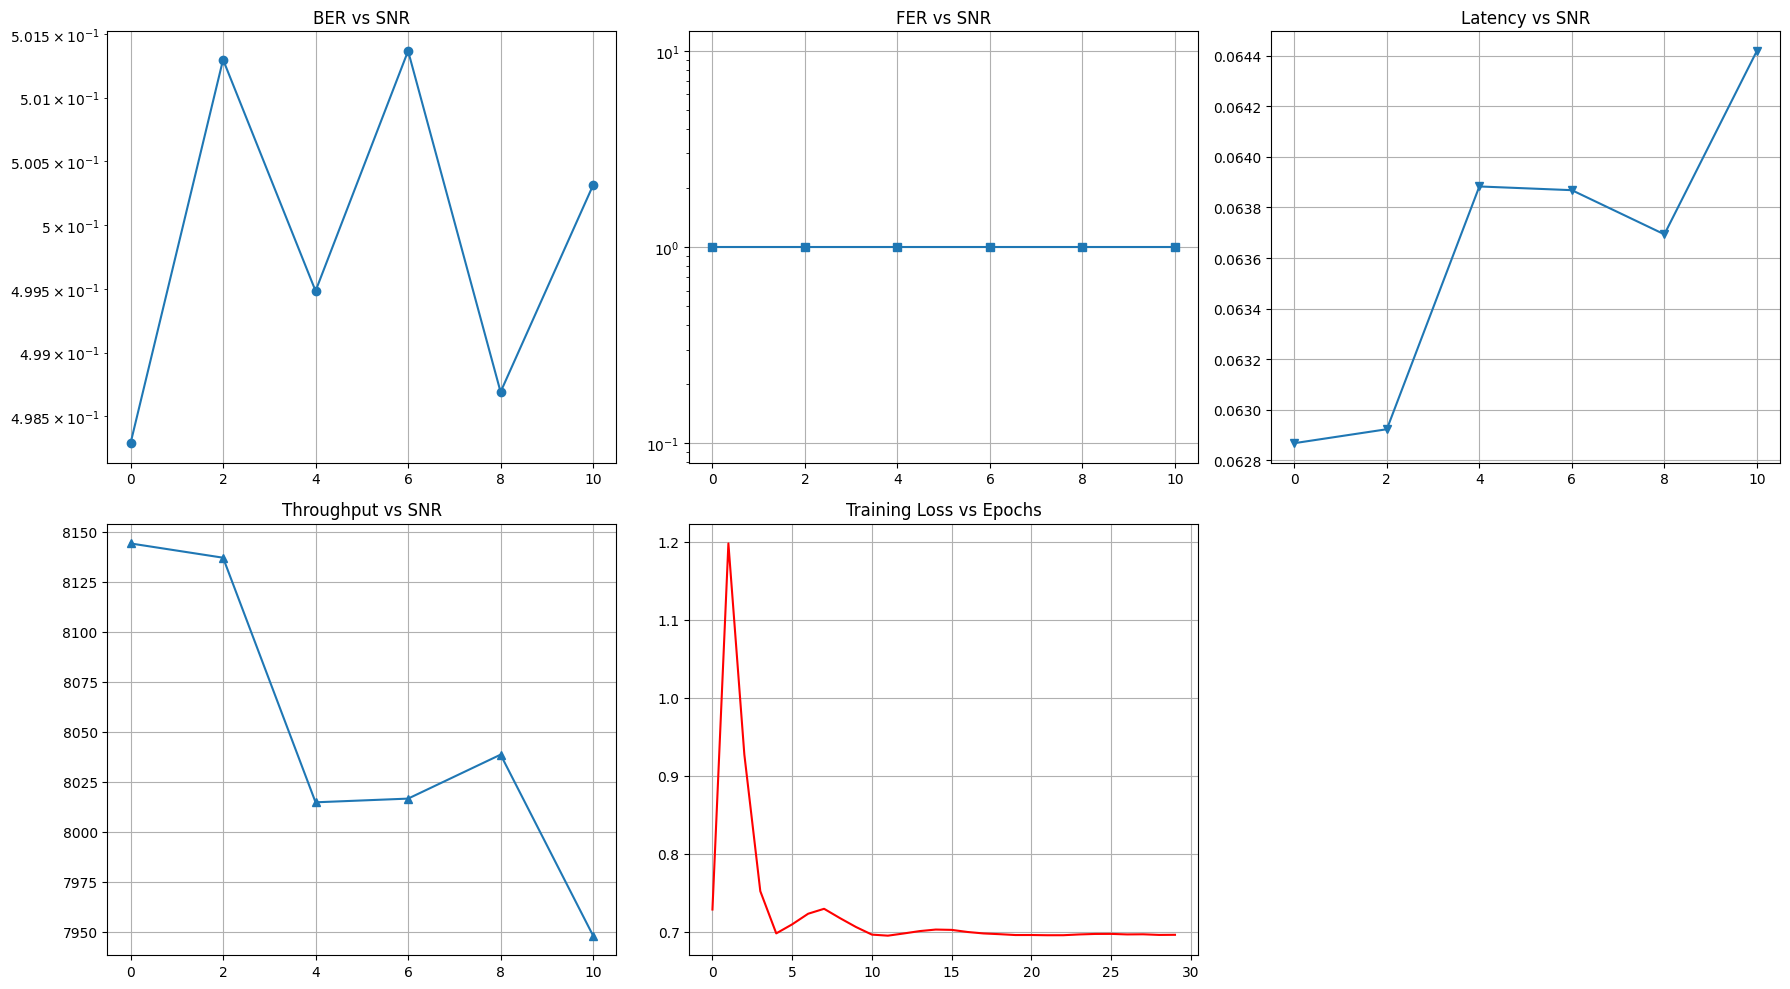

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import time

# --- Configuration ---
N = 512          # Block length
BATCH_SIZE = 64
EPOCHS = 30
SNRS = range(0, 11, 2)

# --- Model Architecture ---
class TransformerDecoder(nn.Module):
    def __init__(self, N, d_model=64):
        super().__init__()
        # Input features are 2 (real and imaginary parts of QPSK)
        self.embedding = nn.Linear(2, d_model)
        encoder_layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=4, batch_first=True)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=3)
        # We output 2 bits for every symbol (N/2 symbols * 2 = N bits)
        self.fc = nn.Linear(d_model, 2)

    def forward(self, x):
        x = self.embedding(x)
        x = self.transformer(x)
        x = self.fc(x) # Shape: [batch, N/2, 2]
        return torch.sigmoid(x.view(x.size(0), -1)) # Shape: [batch, N]

# --- Data & Channel Simulation ---
def get_data(batch_size, N, snr_db):
    bits = torch.randint(0, 2, (batch_size, N)).float()
    # QPSK: Map bits to symbols
    bits_reshaped = bits.view(batch_size, N//2, 2)
    symbols = (1 - 2 * bits_reshaped[:,:,0]) / np.sqrt(2) + 1j * (1 - 2 * bits_reshaped[:,:,1]) / np.sqrt(2)

    # Rayleigh Fading
    h = (torch.randn(batch_size, N//2) + 1j * torch.randn(batch_size, N//2)) / np.sqrt(2)
    snr_lin = 10**(snr_db / 10.0)
    noise = (torch.randn(batch_size, N//2) + 1j * torch.randn(batch_size, N//2)) / np.sqrt(2)
    y = h * symbols + noise / np.sqrt(snr_lin)

    # Features: Real and Imaginary parts
    model_input = torch.stack([y.real, y.imag], dim=-1).float()
    return model_input, bits

# --- Initialization ---
model = TransformerDecoder(N)
optimizer = optim.Adam(model.parameters(), lr=0.001)
criterion = nn.BCELoss()

# --- Training ---
loss_history = []
for epoch in range(EPOCHS):
    y, bits = get_data(BATCH_SIZE, N, 5)
    optimizer.zero_grad()
    out = model(y)
    loss = criterion(out, bits)
    loss.backward()
    optimizer.step()
    loss_history.append(loss.item())
    if (epoch+1) % 5 == 0:
        print(f"Epoch {epoch+1}/{EPOCHS} Loss: {loss.item():.4f}")

# --- Evaluation ---
history = {'ber': [], 'fer': [], 'lat': [], 'thp': []}
for snr in SNRS:
    y, bits = get_data(200, N, snr)
    start = time.time()
    with torch.no_grad():
        preds = (model(y) > 0.5).float()
    duration = time.time() - start

    # Metrics
    ber = torch.mean((preds != bits).float()).item()
    fer = torch.mean((torch.sum(preds != bits, dim=1) > 0).float()).item()

    history['ber'].append(ber)
    history['fer'].append(fer)
    history['lat'].append(duration / 200)
    history['thp'].append((N * 200) / duration)

# --- Visualization ---
fig, axs = plt.subplots(2, 3, figsize=(18, 10))
axs[0,0].semilogy(SNRS, history['ber'], 'o-'); axs[0,0].set_title('BER vs SNR'); axs[0,0].grid(True)
axs[0,1].semilogy(SNRS, history['fer'], 's-'); axs[0,1].set_title('FER vs SNR'); axs[0,1].grid(True)
axs[0,2].plot(SNRS, history['lat'], 'v-'); axs[0,2].set_title('Latency vs SNR'); axs[0,2].grid(True)
axs[1,0].plot(SNRS, history['thp'], '^-'); axs[1,0].set_title('Throughput vs SNR'); axs[1,0].grid(True)
axs[1,1].plot(loss_history, 'r-'); axs[1,1].set_title('Training Loss vs Epochs'); axs[1,1].grid(True)
# Add an empty plot for spacing if needed or another metric
axs[1,2].axis('off')
plt.tight_layout()
plt.show()